In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

In [3]:
prefix = '/mnt/staging/' # or
# prefix = '/scratch/' #for s1n3/4

step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"


fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"

figure_config_root = str(PREPARES / "config") + "/"
CLS_root = str(PREPARES / "CLS") + "/"
mouse='cm125'


In [4]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]

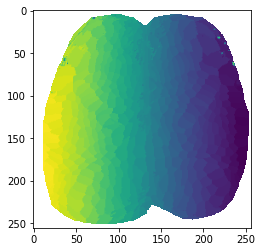

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)


In [6]:
mouse_id = mouse
   
M2_ind = load_pickle(fetch_path_motor+'brightest_frontline_ind-'+mouse_id)
sensory_ind = load_pickle(fetch_path_sensory+'inferred_brightest_ind_'+mouse_id)


extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse_id)
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse_id)
sensory_ind['LM']= sensory_ind['mouth']
sensory_ind['RM'] = extra_extra_ind['right_mouth_sensory']
M2_ind['LM'] = M2_ind['mouth']
M2_ind['RM'] = extra_extra_ind['right_mouth_motor']

sensory_ind['LALM']=75 #extra_ind['ALM']
sensory_ind['RALM']=418
sensory_ind['LV']=extra_ind['LV']
sensory_ind['RV']= extra_ind['RV']
sensory_ind['LRSP'] = 169
sensory_ind['RRSP'] = 296
sensory_ind['RFP_M1_extra']=422 # cm125
sensory_ind['LFP_M1_extra']=76 # cm125


sensory_ind['RholeMOp']=380 # cm125
sensory_ind['LholeMOp']=104 # cm125

sensory_ind['Rposterior']=432 # cm229
sensory_ind['Lposterior']=71 # cm229



M1_ind_from_coherence = load_pickle(fetch_path_M1+'M1_ind_'+mouse)


In [7]:
load_full_corr_map_path = str(PREPARES / "heterogeneity/all-seed") + "/"
all_corr_maps = []
f_h5_corr =  h5py.File(load_full_corr_map_path+mouse+'_all_corr_maps_dict.h5', "r")
for i in range(500):
    all_corr_maps.append(np.array(f_h5_corr['roi-'+str(i)])[:,:,np.newaxis])

all_corr_maps = np.concatenate(all_corr_maps,axis=2)

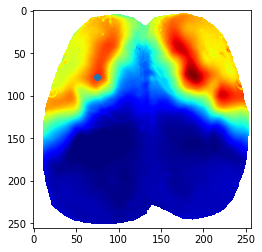

In [8]:
plt.imshow(all_corr_maps[:,:,104],vmin=0,vmax=1,cmap='jet')
ind_here = 380
plt.scatter(node_coords[ind_here,1],node_coords[ind_here,0])
# plt.scatter(node_coords[342,1],node_coords[342,0])

# load full rest data

In [9]:
load_filename = fetch_path_M1+'final_'+mouse+'_MM_jrgeco_'+mouse
hf = h5py.File(load_filename, 'r')
MM_jrgeco_REST = np.array(hf.get('MM_jrgeco'))
hf.close()



In [10]:
H_rest = getH_4D(MM_jrgeco_REST,IDX_sorted)

In [11]:
H_rest.shape

(500, 500, 130)

In [12]:
B = H_rest.shape[-1]
T_PRE_REST = 0
t_stop_resting = np.repeat(160,B)

**get rid of midline**

In [13]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
        mask_midline = np.array(f_midline['mask_midline']).T

In [14]:
fake_M_RM_S1 = H_rest[sensory_ind['RM'],:,:].copy()
# fake_M_RM_S1[:120,:]=np.nan
for i_stop,stop in enumerate(t_stop_resting):
    fake_M_RM_S1[int(t_stop_resting[i_stop]):,i_stop]=np.nan

<AxesSubplot:>

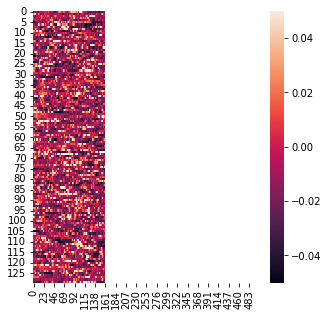

In [15]:
plt.figure(figsize=(5,5))
sns.heatmap(fake_M_RM_S1[:,:].transpose(),vmin=-0.05,vmax=0.05)

(57,)


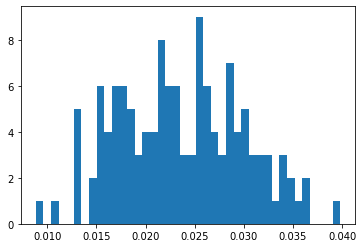

In [16]:
before_running_std = np.nanstd(fake_M_RM_S1[:,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.025
ss_ind = before_running_std>ss
print(np.where(ss_ind==True)[0].shape)


In [17]:
fake_M_RM_S1 = fake_M_RM_S1[:,ss_ind]

H_rest = H_rest[:,:,ss_ind]
MM_jrgeco_REST = MM_jrgeco_REST[:,:,:,ss_ind]
t_stop_resting = t_stop_resting[ss_ind]

In [18]:
B = len(t_stop_resting)
# concat_jrgeco_full_rest = np.empty((256,256,0))
# for i_bout in range(50,B-30):
#     concat_jrgeco_full_rest = np.append(concat_jrgeco_full_rest,
#                     MM_jrgeco_REST[:,:,T_PRE_REST:t_stop_resting[i_bout],i_bout],
#                     axis=2)


concat_jrgeco_full_rest = []
for i_bout in range(B):
    concat_jrgeco_full_rest.append(
                    MM_jrgeco_REST[:,:,T_PRE_REST:t_stop_resting[i_bout],i_bout])
concat_jrgeco_full_rest = np.concatenate(concat_jrgeco_full_rest,axis=2)

In [19]:
concat_jrgeco_full_rest.shape

(256, 256, 9120)

In [20]:
concat_jrgeco_full_rest  = np.multiply(concat_jrgeco_full_rest,np.repeat(mask_midline[:,:,np.newaxis],
                            repeats=concat_jrgeco_full_rest.shape[-1],axis=2))

In [21]:
concat_H = getH(concat_jrgeco_full_rest,IDX_sorted)

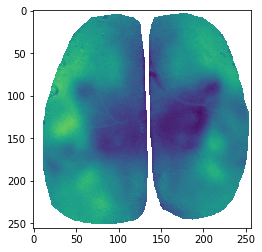

In [22]:
plt.imshow(concat_jrgeco_full_rest[:,:,100])

In [23]:
# OG:
# M2_ind['LHP']= M2_ind_from_coherence['LHP']
# M2_ind['RHP']= M2_ind_from_coherence['RHP']

In [24]:
# use ROI version of HP
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]


In [25]:
# concatenate
all_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT','LFP', 'LHP',  'LW', 'LM', 'LN','LT']
all_bdps_list_M2 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RV','LFP', 'LHP',  'LW', 'LM', 'LN','LV']
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP']
all_bdps_extra = ['RALM','LALM', 'RV', 'LV','RRSP','LRSP','RFP_M1_extra','LFP_M1_extra', 
                 'RholeMOp','LholeMOp',
                  'Rposterior','Lposterior'
                 ]
all_bdps_S1 = [bdp+'_S1' for bdp in all_bdps_list_S1]
all_bdps_M2 = [bdp+'_M2' for bdp in all_bdps_list_M2]
all_bdps_M1 = [bdp+'_M1' for bdp in all_bdps_list_M1]


all_bdps = all_bdps_extra + all_bdps_M2 + all_bdps_S1 + all_bdps_M1


TCs_matrix = np.empty((0,concat_H.shape[1]))

for i_key,key in enumerate(all_bdps_extra):
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[sensory_ind[key],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M2):
    bdp = key.split('_M2')[0]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    small_roi_tcs = np.nanmean(np.nanmean(
concat_jrgeco_full_rest[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    TCs_matrix = np.append(TCs_matrix,
                           small_roi_tcs[np.newaxis,:],
                           axis=0)

for i_key,key in enumerate(all_bdps_S1):
    bdp = key.split('_S1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[sensory_ind[bdp],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M1):
    bdp = key.split('_M1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[M1_ind_from_coherence[bdp],np.newaxis,:],
                           axis=0)
    
# index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
# median_TCs_matrix = np.median(TCs_matrix[index_M2s+[0,1],:],axis=0)


# TCs_matrix[index_M2s+[0,1],:] = TCs_matrix[index_M2s+[0,1],:] - 5*median_TCs_matrix[np.newaxis,:]/len(index_M2s+[0,1]) 
# median_TCs_matrix = median_TCs_matrix#*len(index_M2s+[0]) 

# TCs_matrix = np.append(TCs_matrix,median_TCs_matrix[np.newaxis,:],axis=0)

# TCs_matrix = np.append(TCs_matrix,np.ones((1,concat_H.shape[1])),axis=0)



In [26]:
MM_jrgeco_reshape = concat_jrgeco_full_rest.reshape((256*256,-1))

# quick test on NNLS

In [27]:
total_T = TCs_matrix.shape[1]
to_cut = total_T % 4
if to_cut != 0:
    TCs_matrix = TCs_matrix[:,:-to_cut]
    MM_jrgeco_reshape = MM_jrgeco_reshape[:,:-to_cut]
total_T = total_T - to_cut

In [28]:
dict_ind ={}
split_size = int(total_T/4)
for fold_k in range(4):
    dict_ind[fold_k] = np.arange(split_size*fold_k,split_size*(fold_k+1))
    

**scipy**

In [29]:
import numpy as np
from scipy.optimize import minimize
from scipy.sparse import csr_matrix

def nnls_optimization(A, b):
    """
    Solves the Non-Negative Least Squares (NNLS) problem using constrained optimization.

    Parameters:
    A (numpy.ndarray or scipy.sparse.csr_matrix): The input matrix.
    b (numpy.ndarray): The input vector.

    Returns:
    numpy.ndarray: The solution vector x.
    """
    # Check if A is sparse and convert to csr_matrix if it is not
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    # Objective function: 0.5 * ||Ax - b||^2
    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual)**2

    # Gradient of the objective function
    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    # Initial guess (zeros)
    x0 = np.zeros(A.shape[1])

    # Bounds: 0 <= x
    bounds = [(0, None) for _ in range(A.shape[1])]

    # Optimize using 'L-BFGS-B' method for bound-constrained problems
    result = minimize(objective, x0, method='SLSQP', jac=objective_jac, bounds=bounds, options={'disp': False})

    return result.x

# # Example usage
# if __name__ == "__main__":
#     # Example with a larger dataset
#     np.random.seed(0)
#     A = np.random.rand(1000, 500)
#     b = np.random.rand(1000)
    
#     x = nnls_optimization(A, b)
#     print("Solution:", x)


In [30]:
start = time.time()
temp = Parallel(n_jobs=20)(delayed(nnls_optimization)(np.nan_to_num(TCs_matrix[:,::3].T), 
    np.nan_to_num(MM_jrgeco_reshape[i_region,::3])) for i_region in range(256*256))
full_M = np.vstack(temp)
end = time.time()
print(end - start)

185.05102682113647


In [31]:
mask = concat_jrgeco_full_rest[:,:,100]>-100
mask = mask.astype('float')
mask[mask==0]=np.nan
mask_reshape = mask.reshape((256*256))


W_S1M2M1 = full_M[mask_reshape==1,:]

# add M2 ones
W_S1M2M1_M2 = []
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    W_S1M2M1_M2.append(W_S1M2M1[:,ind_in_list])
W_S1M2M1_M2_sum = np.clip(np.sum(np.stack(W_S1M2M1_M2,0),0), 0, 1)
W_S1M2M1 = np.append(W_S1M2M1,W_S1M2M1_M2_sum[:,np.newaxis],axis=1)
# add cortical ones
W_S1M2M1 = np.append(W_S1M2M1,np.ones((len(W_S1M2M1_M2_sum),1)),axis=1)

W_masked = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked[:]=np.nan
W_masked[mask_reshape==1,:] = W_S1M2M1
W_masked = W_masked.reshape((256,256,-1))




In [32]:
# append median tc 
index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
TCs_matrix=np.append(TCs_matrix,np.median(TCs_matrix[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
# append 1 tc 
TCs_matrix = np.append(TCs_matrix,np.ones((1,TCs_matrix.shape[1])),axis=0)

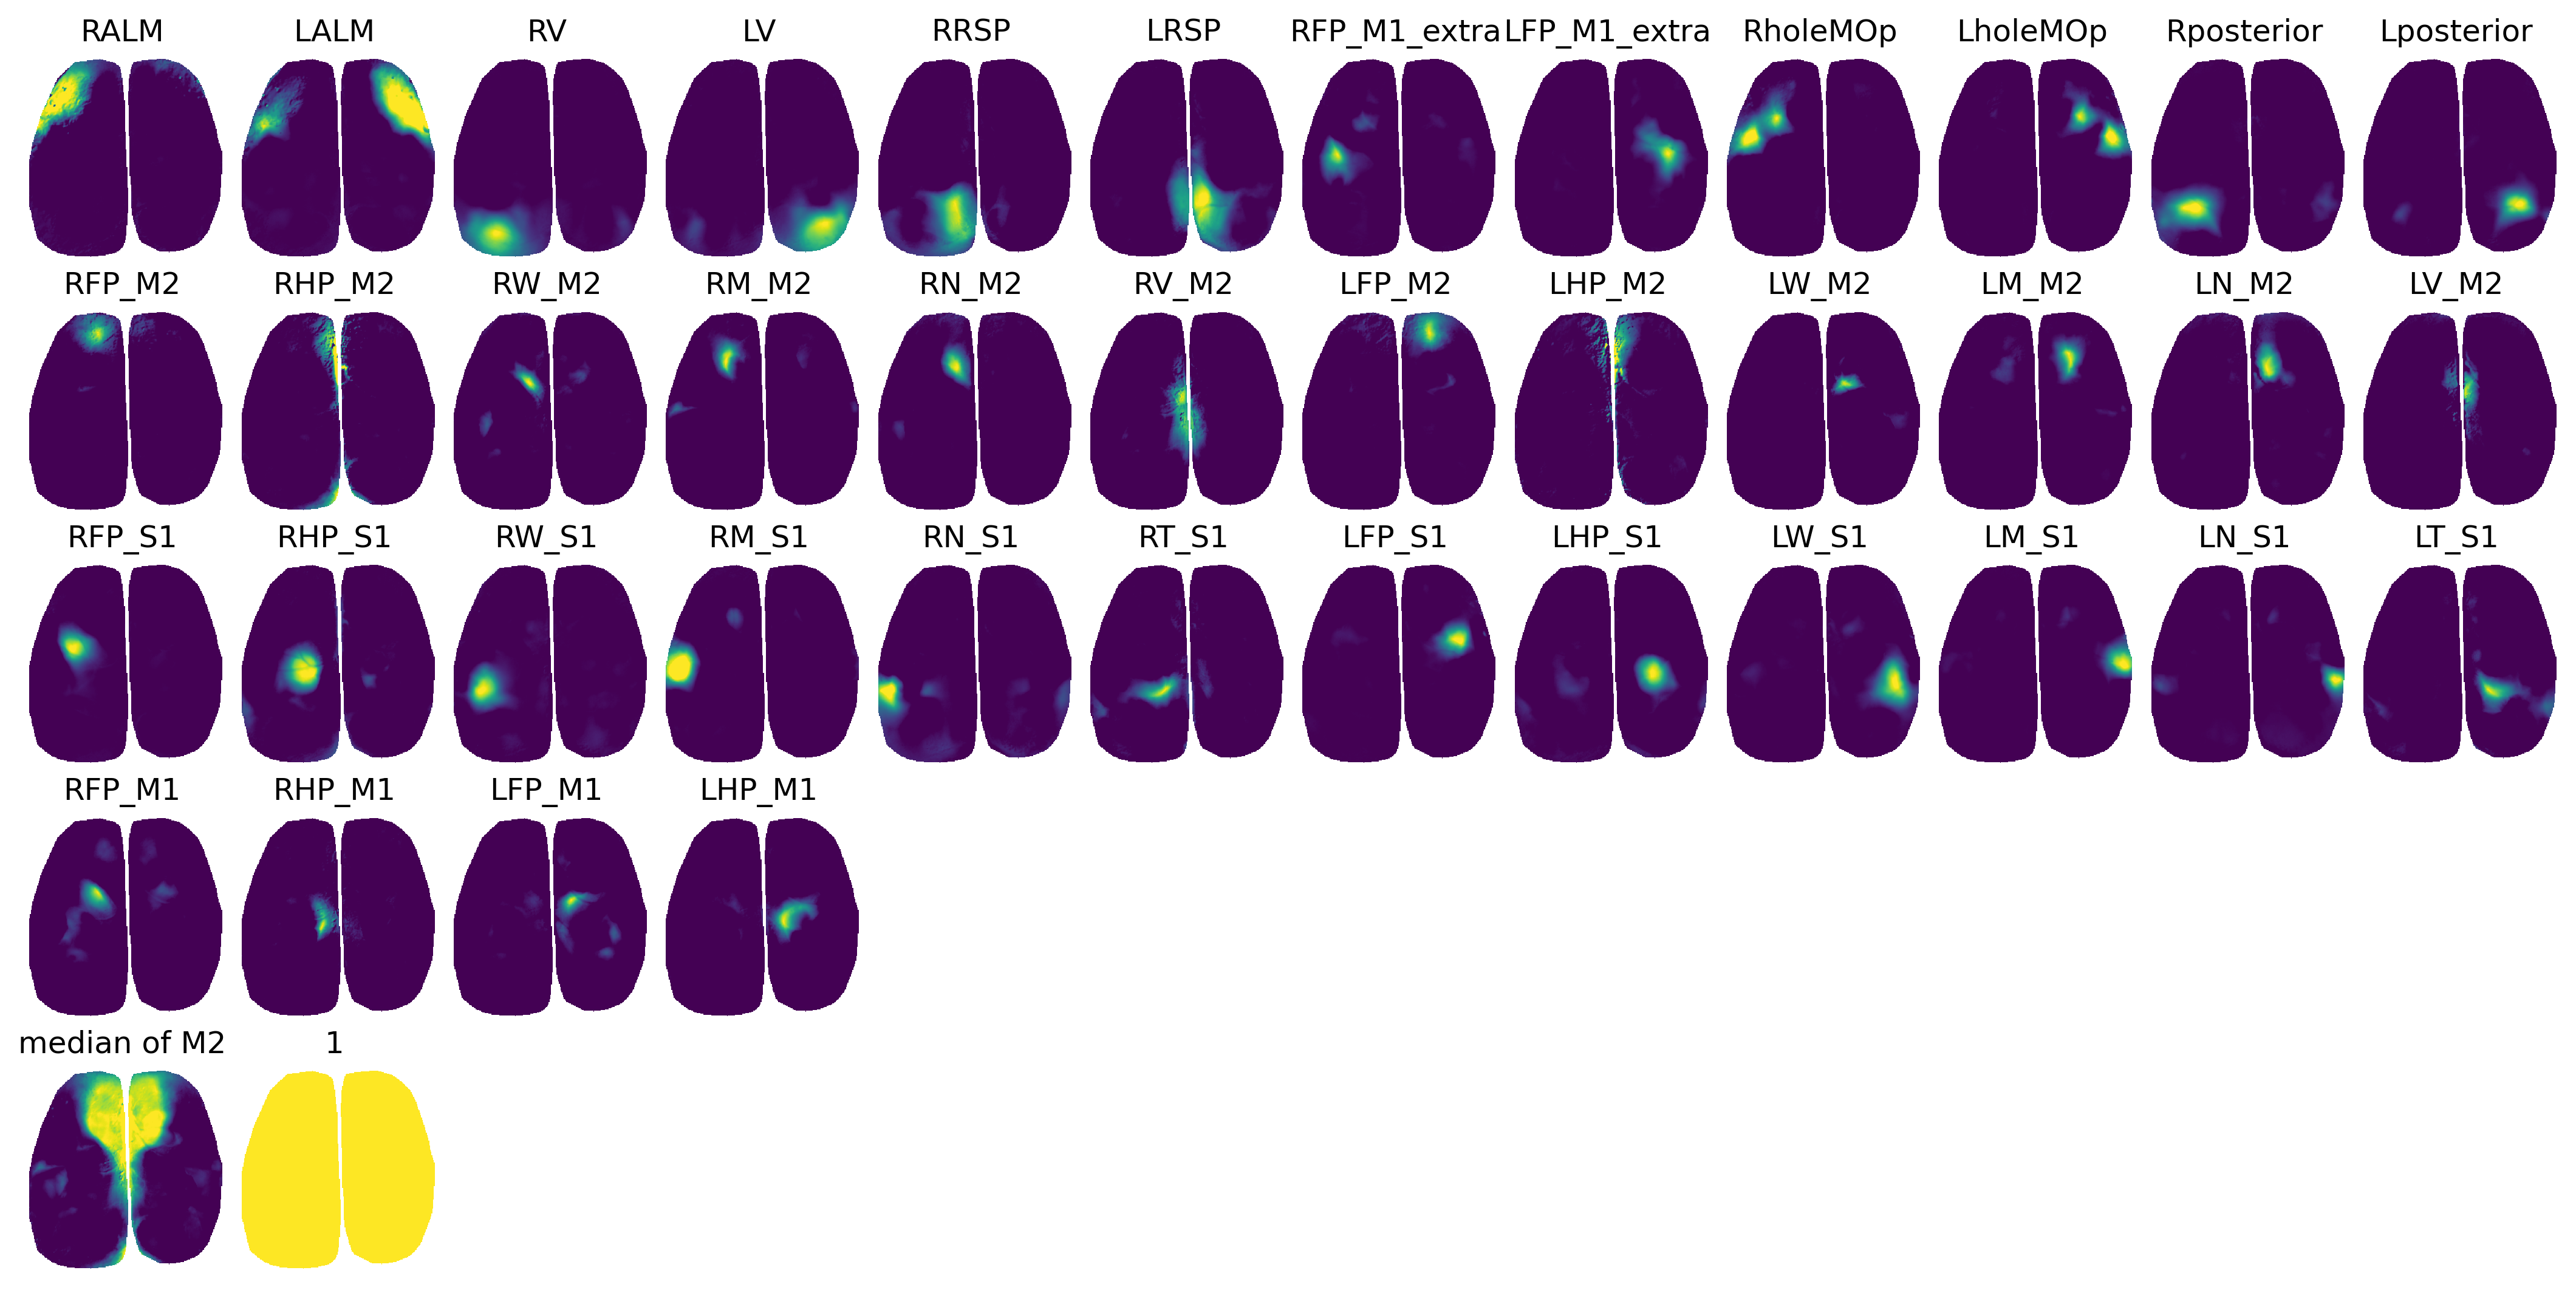

In [33]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+12:y_offset+17,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+18:y_offset+23,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)+2):
    exec("ax{} = fig.add_subplot(gs[y_offset+24:y_offset+29,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5

##########################################
##########################################
for i_key,key in enumerate(all_bdps_extra):
    ind_in_list = all_bdps.index(key)
    W_masked_2show = W_masked[:,:,ind_in_list]        
    exec("ax{}.imshow(W_masked_2show,vmin=0,vmax=1)".format(i_key))
    exec("ax{}.set_title(key)".format(i_key))
    # plt.axis('off')
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_S1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_M1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))

# plot median
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)
exec("ax{}.imshow(W_masked[:,:,-2],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('median of M2')".format(i_entry))

# plot 1
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)+1
exec("ax{}.imshow(W_masked[:,:,-1],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('1')".format(i_entry))

for i_ax in range(50):
    try:
        exec("ax{}.axis('off')".format(i_ax))
    except:
        continue

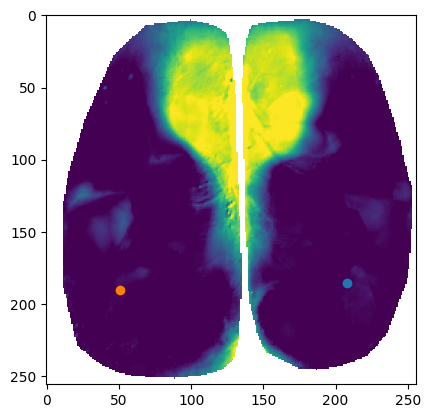

In [34]:
plt.imshow(W_masked[:,:,-2],vmin=0,vmax=1)
ind_here =71
plt.scatter(node_coords[ind_here,1],node_coords[ind_here,0])
ind_here =432
plt.scatter(node_coords[ind_here,1],node_coords[ind_here,0])

# now use the W to fit H

**now adding constraints**

In [35]:
def nnls_optimization_with_constraints(A, b,x_init,constraints):
    """
    Solves the Non-Negative Least Squares (NNLS) problem using constrained optimization.

    Parameters:
    A (numpy.ndarray or scipy.sparse.csr_matrix): The input matrix.
    b (numpy.ndarray): The input vector.

    Returns:
    numpy.ndarray: The solution vector x.
    """
    # Check if A is sparse and convert to csr_matrix if it is not
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    # Objective function: 0.5 * ||Ax - b||^2
    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual)**2

    # Gradient of the objective function
    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    # Initial guess (zeros)
    x0 = x_init #np.zeros(A.shape[1])
    # x0 = np.zeros(A.shape[1])

    
    result = minimize(objective, x0, method='SLSQP',constraints=constraints,jac=objective_jac, options={'disp': False})

    return result.x


In [36]:
index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
  
def return_constraints(H_ROI,median_here,index_M2s,k):
    # Define the constraints
    constraints = []
    for i_M2 in index_M2s:
        constraints.append({
            'type': 'eq',
            'fun': lambda x, i_M2=i_M2: x[i_M2] - (H_ROI[i_M2] - x[-2])
        })
    # constraints.append({'type': 'eq', 'fun': lambda x: x[-2] - k*median_here})  
    constraints.append({'type': 'ineq', 'fun': lambda x: 0.001 - (np.abs(x[-2] - k*median_here))})  
    
    return constraints

# Cross validation (4 folds)

# Correlation matrix

In [39]:
TCs_matrix.shape

(42, 9120)

In [41]:
num_bdps = len(all_bdps)
dict_corrmaps_4folds={}
for i_fold in range(4):
    ind_here = dict_ind[i_fold]  
    ss = TCs_matrix[:,ind_here].shape
    corr_mat = np.corrcoef(TCs_matrix[:num_bdps,ind_here],TCs_matrix[:num_bdps,ind_here])[:num_bdps,num_bdps:]
    dict_corrmaps_4folds[i_fold] = corr_mat

In [42]:
palatte_dict['RALM'] = palatte_dict['ALM']
palatte_dict['LALM'] = 'bisque'
palatte_dict['RRSP'] = palatte_dict['RSP']
palatte_dict['LRSP'] = 'sandybrown'
palatte_dict['RFP_M1_extra'] = 'tab:olive'
palatte_dict['LFP_M1_extra'] = 'tab:cyan'

palatte_dict['RholeMOp'] = 'tab:green'
palatte_dict['LholeMOp'] = 'tab:orange'

palatte_dict['RT'] = 'tab:brown'
palatte_dict['LT'] = 'goldenrod'

palatte_dict['Rposterior'] = 'palegreen'
palatte_dict['Lposterior'] = 'greenyellow'


dict_all_bdps_for_color = {}
for bdp_name in all_bdps:
    if len(bdp_name.split('_'))==2:
        bdp = bdp_name.split('_')[0]
        dict_all_bdps_for_color[bdp_name] = palatte_dict[bdp]
    else:
        dict_all_bdps_for_color[bdp_name] = palatte_dict[bdp_name]
        
dict_area_color = {'extra':'black','M2':'darkgray','S1':'darkred','M1':'darkgreen'}

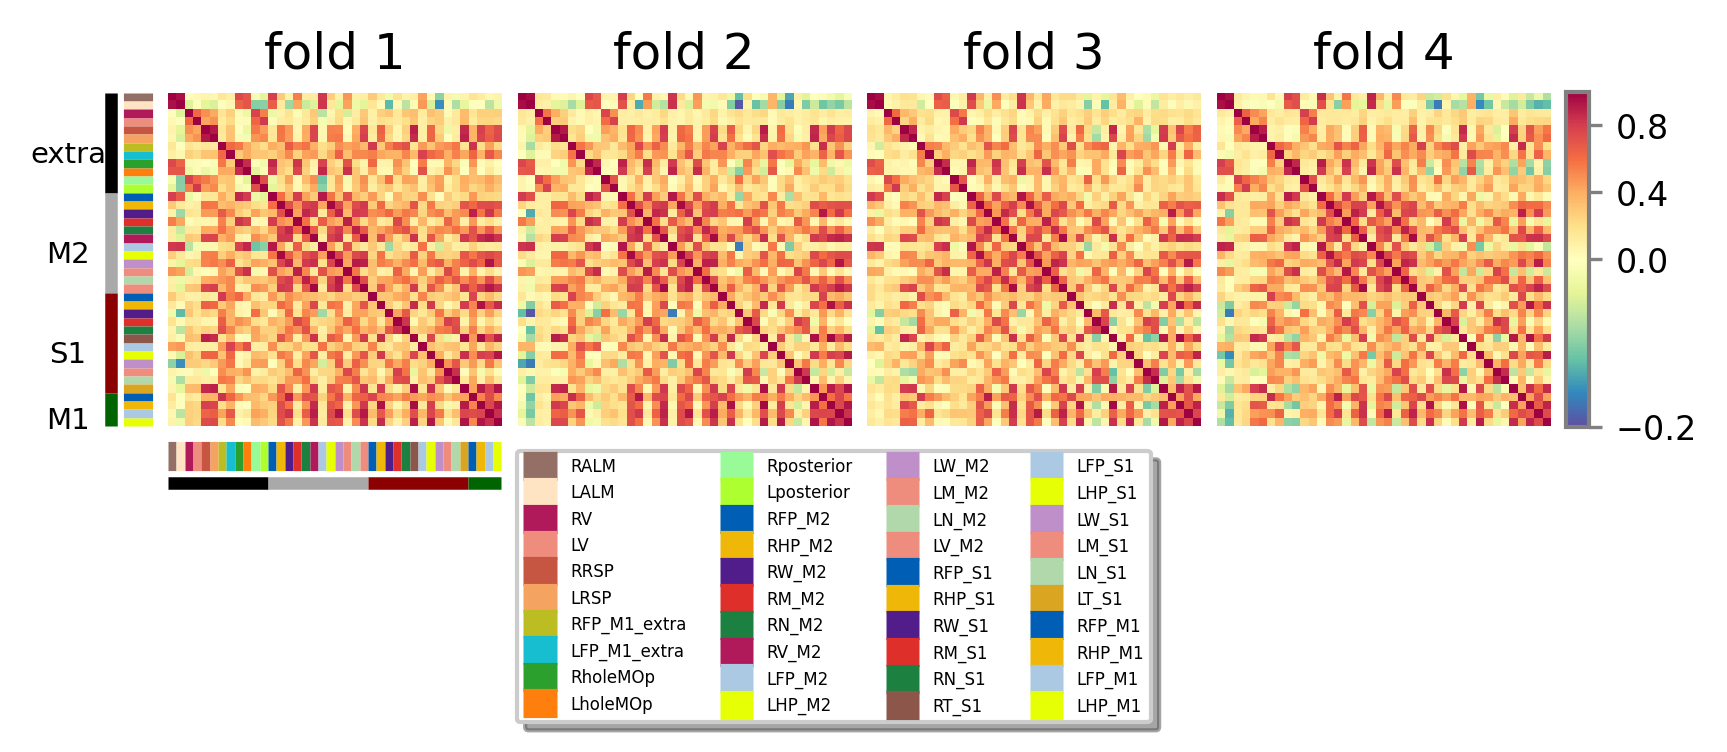

In [43]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5
for i_ax in range(4): # 3 mice S1M1
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.axis('off')".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
ax99 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop-4])
    
divnorm=colors.TwoSlopeNorm(vmin=-0.2, vcenter=0., vmax=1) 
for i_fold in range(4):
    exec("sbp0 = ax{}.imshow(dict_corrmaps_4folds[i_fold] ,cmap='Spectral_r',norm=divnorm)".format(i_fold))
    


cb = fig.colorbar(sbp0, ticks=[-0.2,0,0.4,0.8],cax=ax99,orientation='vertical')
cb.ax.tick_params(labelsize=8,length=3,color='gray')
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
ax99.set_aspect(15)
ax99.set_anchor('W')
# ax0.axis('off')


i_ax=0
exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))
start=-0.5;
for bdp in all_bdps:
    stop = start + 1
    ax2.plot([start,stop],[-0.09,-0.09], color=dict_all_bdps_for_color[bdp],
            transform=trans_x,linewidth=7, clip_on=False,solid_capstyle='butt',label=bdp)
    ax2.plot([-.09,-.09],[start,stop], color=dict_all_bdps_for_color[bdp],
            transform=trans_y,linewidth=7, clip_on=False,solid_capstyle='butt')
    # ax2.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    # if i_ax_temp == 0:
    #     ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")
    start = stop
    
ax2.legend(loc='upper center', bbox_to_anchor=(-0.1, -.05),
          ncol=4, fontsize=4,fancybox=True, shadow=True)


start=-0.5;  
# segregate area (extra, M2, S1, M1)
for i_area,area in enumerate(['all_bdps_extra' ,'all_bdps_M2', 'all_bdps_S1', 'all_bdps_M1']):
    exec("stop = start + len({})".format(area))
    ax2.plot([start,stop],[-0.17,-0.17], color=dict_area_color[area.split('_')[-1]],
            transform=trans_x,linewidth=3, clip_on=False,solid_capstyle='butt')
    ax2.plot([-.17,-.17],[start,stop], color=dict_area_color[area.split('_')[-1]],
            transform=trans_y,linewidth=3, clip_on=False,solid_capstyle='butt')
    ax2.annotate(area.split('_')[-1], xy=(-.3,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")

    start = stop
plt.subplots_adjust(wspace=0.3)

for i_fold in range(4):
    exec("ax{}.set_title('fold {}')".format(i_fold,i_fold+1))
         
         
# plt.savefig('fig-SE-corr-maps-4folds-{}.svg'.format(mouse),format='svg',dpi=300)

# disentangle M2

In [51]:
dict_score_corr = {}
dict_optimal_k = {}
ks = np.linspace(0,1,15)
for i_fold in range(4):
    
    ind_here = dict_ind[i_fold] 
    mask_rest_ind = np.ones(total_T)
    # too large data CM125
    mask_rest_ind[::2]=0
    # too large data CM125    
    mask_rest_ind[ind_here] = 0
    mask_rest_ind = mask_rest_ind.astype(bool)
    
    
    index_M2s_L = [idx for idx, s in enumerate(all_bdps) if np.logical_and('_M2' in s,'L' in s)]
    index_M2s_R = [idx for idx, s in enumerate(all_bdps) if np.logical_and('_M2' in s,'R' in s)]
    index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
        
    # medianM2_TCs_matrix_L = np.median(TCs_matrix[index_M2s_L,:],axis=0)[np.newaxis,:]
    # medianM2_TCs_matrix_R = np.median(TCs_matrix[index_M2s_R,:],axis=0)[np.newaxis,:]
    # medianM2_TCs_matrix = np.median(TCs_matrix[index_M2s,:],axis=0)[np.newaxis,:]


    
    score_corr = []
    for k in ks:
        
        X = MM_jrgeco_reshape[mask_reshape==1,:][:,mask_rest_ind]
        H_ROI = TCs_matrix[:,mask_rest_ind]
        # H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
        median_M2_tc = np.median(H_ROI[index_M2s,:],0)

        start = time.time()
        temp = Parallel(n_jobs=30)(delayed(nnls_optimization_with_constraints)(
            W_S1M2M1, 
            X[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],
            median_M2_tc[i_t],index_M2s,k)) for i_t in range(X.shape[1]))
        H_fitted = np.vstack(temp).T
        end = time.time()
        print(end - start)

        # H_fitted_L = H_fitted.copy()[index_M2s_L,:]
        # H_fitted_R = H_fitted.copy()[index_M2s_R,:]
        H_fitted_L = H_fitted[:,~np.isnan(H_fitted[0,:])].copy()[index_M2s_L,:]
        H_fitted_R = H_fitted[:,~np.isnan(H_fitted[0,:])].copy()[index_M2s_R,:]
        
        ss = H_fitted_L.shape
        corr_mat_L = np.abs(np.corrcoef(H_fitted_L,
                               H_fitted_L)[:ss[0],ss[0]:])     
        ss = H_fitted_R.shape
        corr_mat_R = np.abs(np.corrcoef(H_fitted_R,
                               H_fitted_R)[:ss[0],ss[0]:])  
        
        off_diagonal_entries_L = corr_mat_L[np.triu_indices(ss[0], k = 1)]
        off_diagonal_entries_R = corr_mat_R[np.triu_indices(ss[0], k = 1)]

        score_corr.append( (np.mean(off_diagonal_entries_L) + np.mean(off_diagonal_entries_R))/2 )
    
    dict_score_corr[i_fold] = score_corr
    dict_optimal_k[i_fold] = ks[np.argmin(score_corr)]

147.5766875743866
137.29283022880554
138.6030821800232
137.96890473365784
137.83249688148499
138.3968734741211
137.8393576145172
138.48516178131104
139.59060740470886
139.61237978935242
139.05739855766296
138.72616362571716
137.87733483314514
139.21146512031555
136.88191938400269
137.03619050979614
137.17360591888428
137.74958181381226
137.45950722694397
137.94536924362183
137.60126757621765
138.96932196617126
139.00161290168762
137.10077214241028
138.4404685497284
138.35160040855408
138.06236720085144
136.6050581932068
138.3260419368744
137.9458725452423
138.59847116470337
138.9818217754364
138.93222999572754
138.4773862361908
138.50778579711914
138.1340606212616
138.26506328582764
137.89008903503418
138.2244656085968
138.81926727294922
138.6883020401001
138.10592913627625
138.0965473651886
138.58049821853638
139.0145344734192
139.1117467880249
138.47023582458496
139.9027349948883
139.29613184928894
138.8139271736145
138.50288844108582
139.37511372566223
138.5578532218933
139.50715017

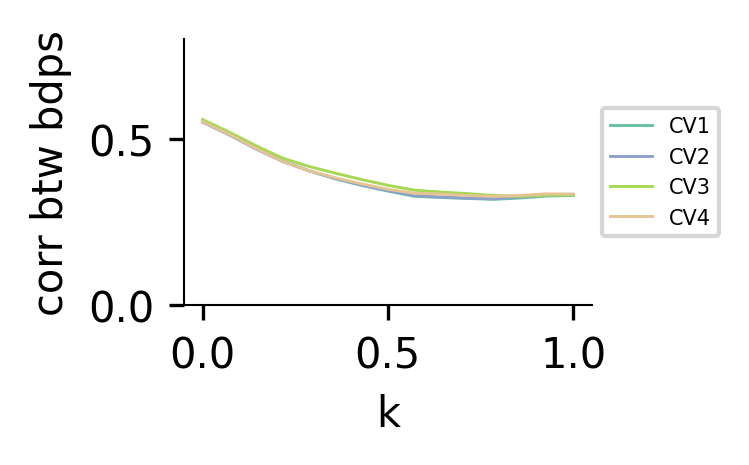

In [53]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+4
x_start = x_offset; x_stop = x_start+6

i_ax = 0
exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    
temp_colors = sns.color_palette("Set2")
for i_fold in range(4):
    ax0.plot(ks,dict_score_corr[i_fold],color=temp_colors[i_fold*2],
             label='CV'+str(i_fold+1),linewidth=0.7)
ax0.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=5)
ax0.set_ylabel('corr btw bdps')
ax0.set_xlabel('k')
ax0.set_ylim([0,0.8])
for axis in ['top','right','left','bottom']:
    for i_ax in range(0,1):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue
for axis in ['top','right']:
    ax0.spines[axis].set_linewidth(0)
    
plt.savefig('fig-SE-corr-against-k-{}.svg'.format(mouse),format='svg',dpi=300)

In [54]:
dict_results_corr = {'dict_score_corr':dict_score_corr,
                    'dict_optimal_k':dict_optimal_k,
                    'ks':ks}
save_pickle(dict_results_corr,'dict_results_corr_'+mouse)

# dict_results_corr = load_pickle('dict_results_corr_'+mouse)
# dict_optimal_k = dict_results_corr['dict_optimal_k']
# dict_score_corr = dict_results_corr['dict_score_corr']

In [56]:
dict_corrmaps_optimized_4folds={}
for i_fold in range(4):
    ind_here = dict_ind[i_fold]
    optimal_k = dict_optimal_k[i_fold]
    optimal_k = 0.5
    index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]

    X = MM_jrgeco_reshape[mask_reshape==1,:][:,ind_here]
    H_ROI = TCs_matrix[:,ind_here]
    # H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
    median_M2_tc = np.median(H_ROI[index_M2s,:],0)

    start = time.time()
    temp = Parallel(n_jobs=20)(delayed(nnls_optimization_with_constraints)(
        W_S1M2M1, 
        X[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],
        median_M2_tc[i_t],index_M2s,optimal_k)) for i_t in range(X.shape[1]))
    H_fitted = np.vstack(temp).T
    end = time.time()
    print(end - start)

        
    
    corr_map = np.corrcoef(H_fitted[:num_bdps,:],
       H_fitted[:num_bdps,:])[:num_bdps,num_bdps:]     

    dict_corrmaps_optimized_4folds[i_fold] = corr_map
    

141.81407737731934
134.87592673301697
134.3037314414978
135.88164567947388


In [57]:
dict_corrmaps_raw_4folds={}
for i_fold in range(4):
    ind_here = dict_ind[i_fold]
    # optimal_k = dict_optimal_k[i_fold]
    # optimal_k = 0.45
    index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]

    X = MM_jrgeco_reshape[mask_reshape==1,:][:,ind_here]
    H_ROI = TCs_matrix[:,ind_here]
    # H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
    median_M2_tc = np.median(H_ROI[index_M2s,:],0)

    start = time.time()
    temp = Parallel(n_jobs=20)(delayed(nnls_optimization_with_constraints)(
        W_S1M2M1, 
        X[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],
        median_M2_tc[i_t],index_M2s,0)) for i_t in range(X.shape[1]))
    H_fitted = np.vstack(temp).T
    end = time.time()
    print(end - start)

        
    
    corr_map = np.corrcoef(H_fitted[:num_bdps,:],
       H_fitted[:num_bdps,:])[:num_bdps,num_bdps:]     

    dict_corrmaps_raw_4folds[i_fold] = corr_map
    

135.3100175857544
136.38351964950562
135.16175413131714
134.764963388443


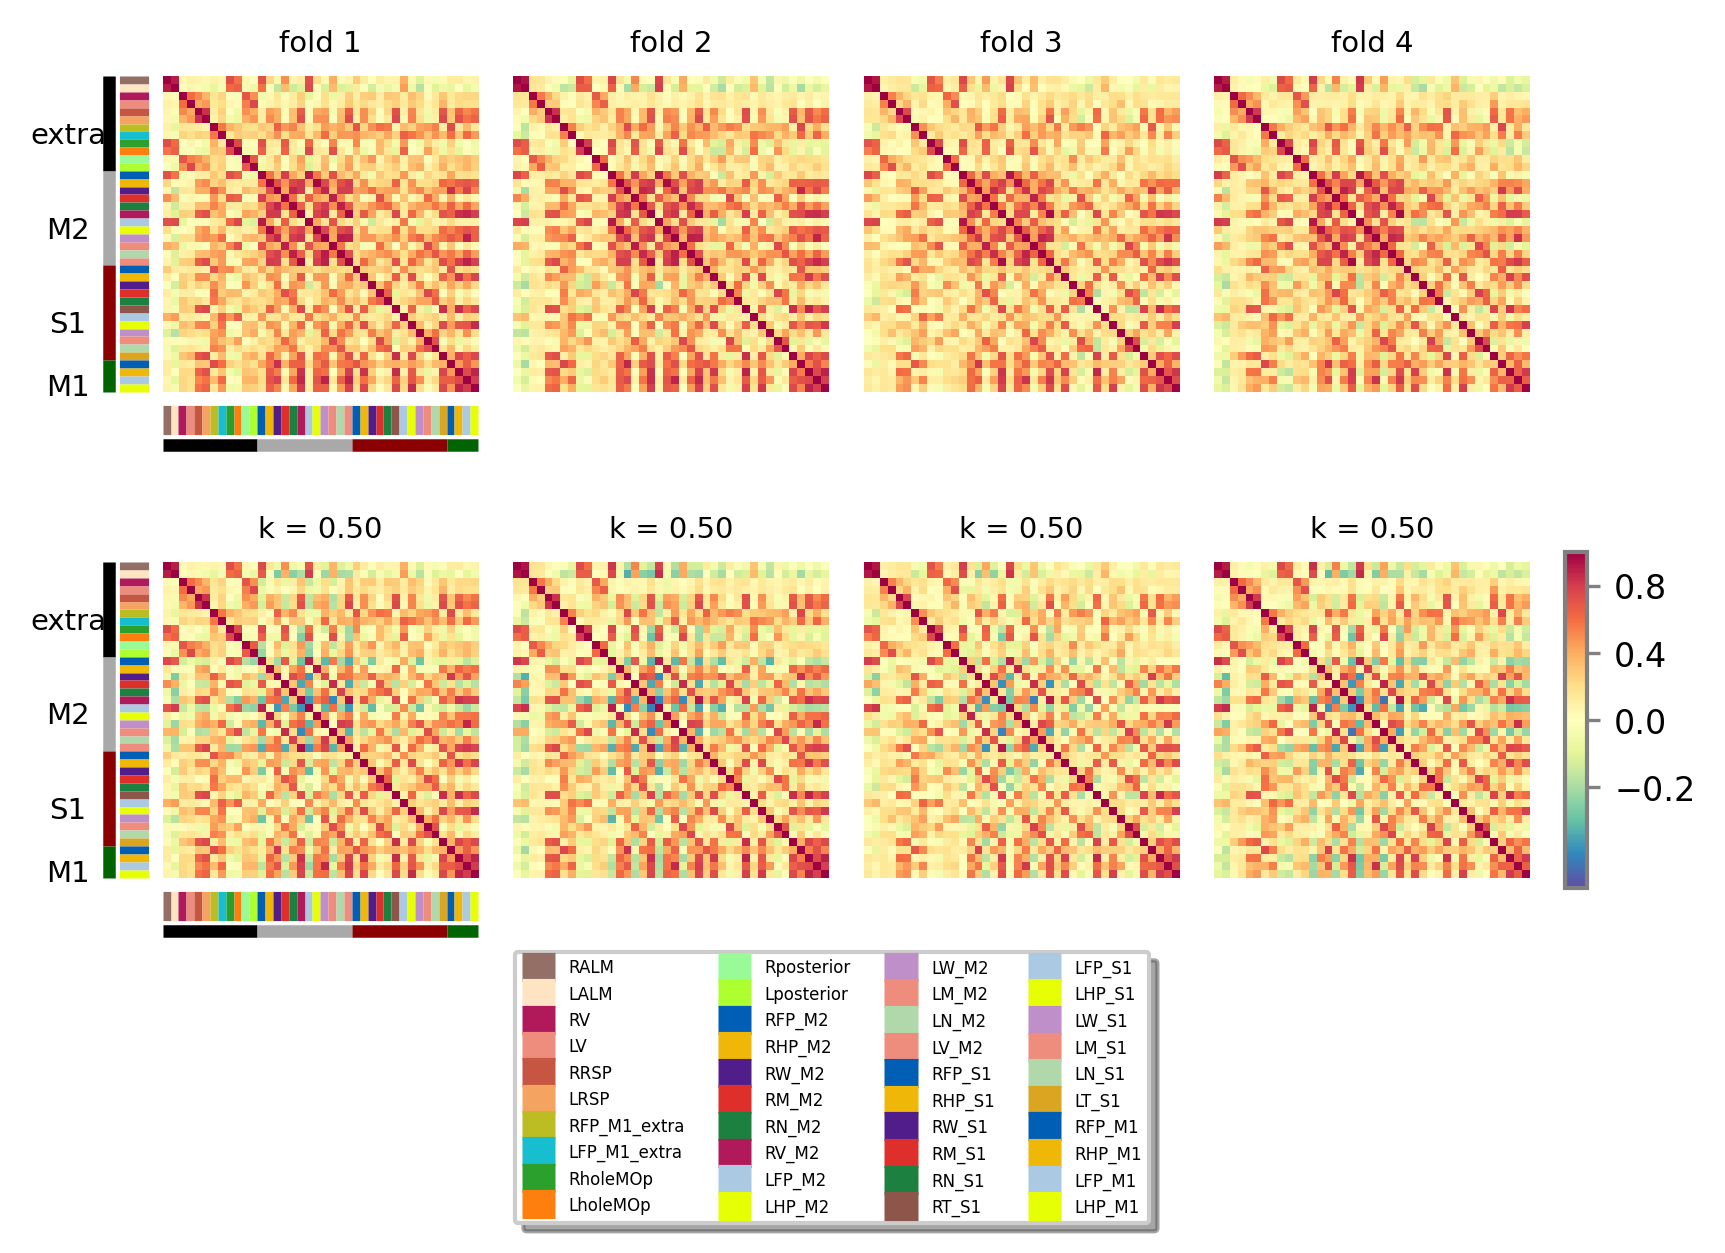

In [59]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5
for i_ax in range(4): 
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.axis('off')".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
y_start = y_offset+7; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5  
for i_ax in range(4,4+4): 
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    exec("ax{}.axis('off')".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
ax99 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop-4])
    
divnorm=colors.TwoSlopeNorm(vmin=-0.5, vcenter=0., vmax=1) 
for i_fold in range(4):
    exec("sbp0 = ax{}.imshow(dict_corrmaps_raw_4folds[i_fold] ,cmap='Spectral_r',norm=divnorm)".format(i_fold))
    
    
for i_fold,i_ax in enumerate(range(4,4+4)):
    exec("sbp0 = ax{}.imshow(dict_corrmaps_optimized_4folds[i_fold] ,cmap='Spectral_r',norm=divnorm)".format(i_ax))
    


cb = fig.colorbar(sbp0, ticks=[-0.2,0,0.4,0.8],cax=ax99,orientation='vertical')
cb.ax.tick_params(labelsize=8,length=3,color='gray')
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
ax99.set_aspect(15)
ax99.set_anchor('W')
# ax0.axis('off')


for i_count, i_ax in enumerate([0,4]):

    exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
    exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))
    start=-0.5;
    for bdp in all_bdps:
        stop = start + 1
        if i_count==0:
            ax2.plot([start,stop],[-0.09,-0.09], color=dict_all_bdps_for_color[bdp],
                    transform=trans_x,linewidth=7, clip_on=False,solid_capstyle='butt',label=bdp)
        else:
            ax2.plot([start,stop],[-0.09,-0.09], color=dict_all_bdps_for_color[bdp],
                transform=trans_x,linewidth=7, clip_on=False,solid_capstyle='butt')
        ax2.plot([-.09,-.09],[start,stop], color=dict_all_bdps_for_color[bdp],
                transform=trans_y,linewidth=7, clip_on=False,solid_capstyle='butt')
        # ax2.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
        # if i_ax_temp == 0:
        #     ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")
        start = stop



    start=-0.5;  
    # segregate area (extra, M2, S1, M1)
    for i_area,area in enumerate(['all_bdps_extra' ,'all_bdps_M2', 'all_bdps_S1', 'all_bdps_M1']):
        exec("stop = start + len({})".format(area))
        ax2.plot([start,stop],[-0.17,-0.17], color=dict_area_color[area.split('_')[-1]],
                transform=trans_x,linewidth=3, clip_on=False,solid_capstyle='butt')
        ax2.plot([-.17,-.17],[start,stop], color=dict_area_color[area.split('_')[-1]],
                transform=trans_y,linewidth=3, clip_on=False,solid_capstyle='butt')
        ax2.annotate(area.split('_')[-1], xy=(-.3,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")

        start = stop
        
ax2.legend(loc='upper center', bbox_to_anchor=(-0.1, -1.75),
              ncol=4, fontsize=4,fancybox=True, shadow=True)
plt.subplots_adjust(wspace=1)

for i_fold in range(4):
    exec("ax{}.set_title('fold {}',fontsize=7)".format(i_fold,i_fold+1))
         
        
for i_fold,i_ax in enumerate(range(4,4+4)):
    # optimal_k = dict_optimal_k[i_fold]
    exec("ax{}.set_title('k = {:0.2f}',fontsize=7)".format(i_ax,0.5))
         
         
plt.savefig('fig-SE-corr-maps-optimized_4folds_{}.svg'.format(mouse),format='svg',dpi=300)

# final k

In [88]:
final_k = np.median([dict_optimal_k[i_fold] for i_fold in range(4)])
print(final_k)

0.5789473684210527


In [83]:
final_k = 0.578

In [84]:
    
save_dict = {'full_M':full_M,
             # 'full_M_back_in_shape':full_M_back_in_shape,
            # 'full_nnls_spatial':full_nnls_spatial,
             'index_M2s':index_M2s,
             'W_S1M2M1':W_S1M2M1,
             'mask':mask,
             'TCs_matrix':TCs_matrix,
             'all_bdps_w_order_nnls':all_bdps,
             # 'mask_M2':mask_M2,
             'all_bdps_w_order':all_bdps,    
             'final_k':final_k
            }
save_path = CLS_root
save_pickle(save_dict,save_path+'M2S1M1_NNLS_spatial_'+mouse)

